<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME_640_01_Design_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Python as an Engineering Design Calculator

**ME 640 - Optimum Design Methods | Module 1 - Formulation and Computational Foundations**  
**Format:** guided notebook (read -> predict -> run -> interpret -> extend)

## Learning objectives
- Read and modify basic Python expressions, arrays, functions, and plots
- Translate a cantilever-beam design into variables, responses, constraints, and an objective
- Use a grid search to expose tradeoffs and verify feasibility

## Responsible AI checkpoint
You may use a generative-AI assistant to explain syntax, propose tests, or critique your interpretation. You remain responsible for the formulation, units, constraints, verification, and final engineering claims. Record any material AI assistance in the reflection cell at the end.

## How to work with this notebook

1. Read the engineering question before running code.
2. Run cells in order. Change only the marked inputs during the guided portion.
3. Interpret plots and solver messages in engineering terms.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats
np.set_printoptions(precision=4, suppress=True)
plt.style.use("seaborn-v0_8-whitegrid")
rng = np.random.default_rng(640)

## Case study: minimum-mass rectangular cantilever

A 1.2 m aluminum cantilever carries a 2.0 kN tip load. Choose width $b$ and height $h$ to minimize mass while satisfying bending stress and tip-deflection limits.

$$m=\rho Lbh,\quad \sigma=\frac{6PL}{bh^2},\quad \delta=\frac{4PL^3}{Ebh^3}$$

Use $E=69$ GPa, $\rho=2700$ kg/m³, $\sigma_{allow}=120$ MPa, and $\delta_{allow}=3$ mm. Bounds: $20\le b\le80$ mm and $30\le h\le150$ mm.

**Before you run:** Which dimension should have the larger influence on deflection? Explain from the exponent in the equation.

In [ ]:
# Scalar calculations: one candidate design
L, P, E, rho = 1.2, 2000.0, 69e9, 2700.0
sigma_allow, delta_allow = 120e6, 0.003
b, h = 0.050, 0.100

mass = rho*L*b*h
stress = 6*P*L/(b*h**2)
deflection = 4*P*L**3/(E*b*h**3)
print(f"mass = {mass:.2f} kg")
print(f"stress = {stress/1e6:.1f} MPa")
print(f"deflection = {deflection*1e3:.2f} mm")
print("feasible?", stress <= sigma_allow and deflection <= delta_allow)

mass = 16.20 kg
stress = 28.8 MPa
deflection = 4.01 mm
feasible? False


### Functions make the model reusable

A function packages equations so the same model can evaluate many designs. Inputs and outputs should carry documented units.

In [ ]:
def beam_responses(b, h):
    """Inputs b,h in m; returns mass kg, stress Pa, deflection m."""
    m = rho*L*b*h
    s = 6*P*L/(b*h**2)
    d = 4*P*L**3/(E*b*h**3)
    return m, s, d

for h_mm in [60, 90, 120]:
    m, s, d = beam_responses(0.05, h_mm/1000)
    print(h_mm, "mm ->", round(m,2), "kg,", round(d*1e3,2), "mm")

60 mm -> 9.72 kg, 18.55 mm
90 mm -> 14.58 kg, 5.5 mm
120 mm -> 19.44 kg, 2.32 mm


## Grid Search Optimization

The grid search method exhaustively evaluates a range of design parameters (`b` and `h`) to find a solution that satisfies constraints and optimizes the objective function (mass). We will visualize the design space, the regions defined by each constraint, the feasible region, and the optimal design found.

In [ ]:
# Define the design space for b and h (in mm), then convert to meters for calculations
b_min_mm, b_max_mm = 20, 80
h_min_mm, h_max_mm = 30, 150

# Create a grid of b and h values (e.g., 50 steps for each)
b_vals_mm = np.linspace(b_min_mm, b_max_mm, 50)
h_vals_mm = np.linspace(h_min_mm, h_max_mm, 50)

B, H = np.meshgrid(b_vals_mm / 1000, h_vals_mm / 1000) # Convert to meters

# Calculate responses for each point in the grid
m_grid, s_grid, d_grid = beam_responses(B, H)

# Check feasibility for each point
feasible_stress = s_grid <= sigma_allow
feasible_deflection = d_grid <= delta_allow
is_feasible = feasible_stress & feasible_deflection

# Find the minimum mass among feasible designs
min_mass = np.inf
optimal_b, optimal_h = None, None

for i in range(B.shape[0]):
    for j in range(B.shape[1]):
        if is_feasible[i, j]:
            if m_grid[i, j] < min_mass:
                min_mass = m_grid[i, j]
                optimal_b = B[i, j]
                optimal_h = H[i, j]

m_grid_opt, s_grid_opt, d_grid_opt = beam_responses(optimal_b, optimal_h)
print(f" Grid mass: {m_grid_opt:.2f} kg")
print(f" Grid b: {optimal_b*1000:.1f} mm")
print(f" Grid h: {optimal_h*1000:.1f} mm")
print(f" Stress = {s_grid_opt/1e6:.1f} MPa (allowable: {sigma_allow/1e6:.1f} MPa)")
print(f" Deflection = {d_grid_opt*1000:.2f} mm (allowable: {delta_allow*1000:.1f} mm)")
print(f" Feasible: {s_grid_opt <= sigma_allow and d_grid_opt <= delta_allow}")


 Grid mass: 9.72 kg
 Grid b: 20.0 mm
 Grid h: 150.0 mm
 Stress = 32.0 MPa (allowable: 120.0 MPa)
 Deflection = 2.97 mm (allowable: 3.0 mm)
 Feasible: True


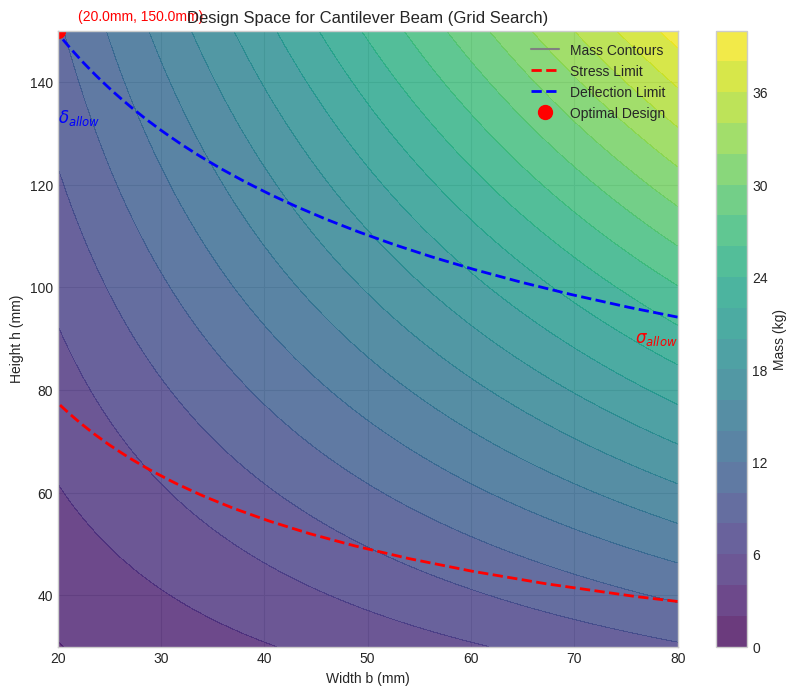

In [ ]:
# Plot the design space, constraints, and optimal design

fig, ax = plt.subplots(figsize=(10, 8))

contour_mass = ax.contourf(B * 1000, H * 1000, m_grid, levels=20, cmap='viridis', alpha=0.8)
fig.colorbar(contour_mass, ax=ax, label='Mass (kg)')

# Plot stress constraint boundary
ax.contour(B * 1000, H * 1000, s_grid, levels=[sigma_allow], colors='red', linestyles='dashed', linewidths=2)
ax.text(b_max_mm, 0.5 * (h_min_mm + h_max_mm), r'$\sigma_{allow}$', color='red', fontsize=12, ha='right', va='center')

# Plot deflection constraint boundary
ax.contour(B * 1000, H * 1000, d_grid, levels=[delta_allow], colors='blue', linestyles='dashed', linewidths=2)
ax.text(b_min_mm, 0.9 * h_max_mm, r'$\delta_{allow}$', color='blue', fontsize=12, ha='left', va='top')

# Mark the optimal design
if optimal_b is not None and optimal_h is not None:
    ax.plot(optimal_b * 1000, optimal_h * 1000, 'o', color='red', markersize=10, label='Optimal Design')
    ax.text(optimal_b * 1000 + 2, optimal_h * 1000 + 2, f'({optimal_b*1000:.1f}mm, {optimal_h*1000:.1f}mm)', color='red', fontsize=10)

ax.set_title('Design Space for Cantilever Beam (Grid Search)')
ax.set_xlabel('Width b (mm)')
ax.set_ylabel('Height h (mm)')
ax.set_xlim(b_min_mm, b_max_mm)
ax.set_ylim(h_min_mm, h_max_mm)

# Custom legend handles
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

legend_elements = [
    Line2D([0], [0], color='gray', linestyle='-', label='Mass Contours'),
    Line2D([0], [0], color='red', lw=2, ls='dashed', label='Stress Limit'),
    Line2D([0], [0], color='blue', lw=2, ls='dashed', label='Deflection Limit'),
    Line2D([0], [0], marker='o', color='red', label='Optimal Design',
           markerfacecolor='red', markersize=10, linestyle='None')
]

ax.legend(handles=legend_elements, loc='upper right')
ax.grid(True)
plt.show()


## Unconstrained Optimization: Penalized Objective Function

For unconstrained optimization methods, we transform the constrained problem into an unconstrained one by adding penalty terms to the objective function for any constraint violations. The goal is to minimize this new penalized objective function.

Our objective function will be:

$$ f(b, h) = \text{mass}(b, h) + P_\sigma \cdot \max(0, \sigma(b, h) - \sigma_{allow})^2 + P_\delta \cdot \max(0, \delta(b, h) - \delta_{allow})^2 + P_b \cdot (\max(0, b - b_{max})^2 + \max(0, b_{min} - b)^2) + P_h \cdot (\max(0, h - h_{max})^2 + \max(0, h_{min} - h)^2) $$

Where $P$ terms are large penalty coefficients, and the $\max(0, \cdot)^2$ ensures penalties are only applied for violations.

In [ ]:
# Define the penalized objective function and its derivatives

# Define bounds for b and h in meters for use in the objective function
b_min, b_max = b_min_mm / 1000, b_max_mm / 1000
h_min, h_max = h_min_mm / 1000, h_max_mm / 1000

# Penalty coefficients (can be tuned)
P_sigma = 1e5  # Penalty for stress violation
P_delta = 1e8  # Penalty for deflection violation
P_b = 1e7      # Penalty for b bounds violation
P_h = 1e7      # Penalty for h bounds violation

def penalized_objective(x):
    b, h = x
    # Unpack design variables and convert to appropriate units if necessary
    # (already handled as b, h are expected in meters for beam_responses)

    m, s, d = beam_responses(b, h);

    # Calculate penalty terms
    penalty_stress = P_sigma * (max(0, s - sigma_allow)**2)
    penalty_deflection = P_delta * (max(0, d - delta_allow)**2)
    penalty_b_lower = P_b * (max(0, b_min - b)**2)
    penalty_b_upper = P_b * (max(0, b - b_max)**2)
    penalty_h_lower = P_h * (max(0, h_min - h)**2)
    penalty_h_upper = P_h * (max(0, h - h_max)**2)

    total_penalty = penalty_stress + penalty_deflection + \
                    penalty_b_lower + penalty_b_upper + \
                    penalty_h_lower + penalty_h_upper

    return m + total_penalty


def gradient_penalized_objective(x):
    b, h = x

    # Numerical approximation of gradients for simplicity,
    # analytical derivatives would be more accurate but more complex
    # using scipy.optimize.approx_fprime for this
    epsilon = 1e-6
    grad = optimize.approx_fprime(x, penalized_objective, epsilon) # Corrected: pass scalar epsilon directly
    return grad


def hessian_penalized_objective(x):
    b, h = x
    # Numerical approximation of Hessian using finite differences
    # from scipy.optimize._numdiff
    # This is more complex to implement manually, so for demonstration,
    # we will rely on a generic numerical approximation or let the optimizer handle it.
    # For this example, if using a solver that requires an explicit Hessian,
    # we would define it here. For now, we'll return a placeholder or use a solver
    # that approximates it internally (e.g., trust-region methods in scipy).
    # For Newton's method, we'll approximate it here as well for now.

    # A simple way to approximate the Hessian numerically is using a central difference scheme.
    # For this problem, let's use a function that can approximate the Hessian.
    # For now, let's use a numerical approximation by perturbing the gradient.
    H = np.zeros((2, 2))
    epsilon = 1e-6
    # Column 0 for partial derivative wrt b
    x_plus_b = x + np.array([epsilon, 0])
    x_minus_b = x - np.array([epsilon, 0])
    grad_plus_b = gradient_penalized_objective(x_plus_b)
    grad_minus_b = gradient_penalized_objective(x_minus_b)
    H[:, 0] = (grad_plus_b - grad_minus_b) / (2 * epsilon)

    # Column 1 for partial derivative wrt h
    x_plus_h = x + np.array([0, epsilon])
    x_minus_h = x - np.array([0, epsilon])
    grad_plus_h = gradient_penalized_objective(x_plus_h)
    grad_minus_h = gradient_penalized_objective(x_minus_h)
    H[:, 1] = (grad_plus_h - grad_minus_h) / (2 * epsilon)

    return H


# Example usage:
x_initial = np.array([0.05, 0.10]) # Initial guess (b, h) in meters
obj_val = penalized_objective(x_initial)
grad_val = gradient_penalized_objective(x_initial)
hess_val = hessian_penalized_objective(x_initial)

print(f"Initial objective value: {obj_val:.2f}")
print(f"Initial gradient: {grad_val}")
print(f"Initial Hessian:\n{hess_val}")

Initial objective value: 117.60
Initial gradient: [-15814.359  -24045.0569]
Initial Hessian:
[[1929932.5302 2414017.0609]
 [2413997.7981 3858187.8456]]


In [ ]:
m_initial, s_initial, d_initial = beam_responses(x_initial[0], x_initial[1])

print(f"\nInitial design:")
print(f"  b = {x_initial[0]*1000:.2f} mm")
print(f"  h = {x_initial[1]*1000:.2f} mm")
print(f"  Mass = {m_initial:.2f} kg")
print(f"  Stress = {s_initial/1e6:.1f} MPa (allowable: {sigma_allow/1e6:.1f} MPa)")
print(f"  Deflection = {d_initial*1000:.2f} mm (allowable: {delta_allow*1000:.1f} mm)")
print(f"  Feasible: {s_initial <= sigma_allow and d_initial <= delta_allow}")


Initial design:
  b = 50.00 mm
  h = 100.00 mm
  Mass = 16.20 kg
  Stress = 28.8 MPa (allowable: 120.0 MPa)
  Deflection = 4.01 mm (allowable: 3.0 mm)
  Feasible: False


### Newton's Method

Newton's method is an iterative optimization algorithm that uses both the first and second derivatives (gradient and Hessian) of the objective function to find the minimum. It approximates the function locally with a quadratic function and finds the minimum of that approximation. The update rule is:

$$ \mathbf{x}_{k+1} = \mathbf{x}_k - [\mathbf{H}f(\mathbf{x}_k)]^{-1} \nabla f(\mathbf{x}_k) $$

Where $\mathbf{H}f$ is the Hessian matrix and $\nabla f$ is the gradient vector.

In [ ]:
# Implementation of Newton's Method

iterations_newton = []

def newton_method(x_start, max_iter=100, tol=1e-6):
    x = np.array(x_start, dtype=float)
    iterations_newton.append(x.copy())

    for i in range(max_iter):
        grad = gradient_penalized_objective(x)
        hess = hessian_penalized_objective(x)

        # Check for convergence
        if np.linalg.norm(grad) < tol:
            print(f"Newton's method converged in {i} iterations.")
            break

        # Calculate step direction using inverse Hessian
        try:
            step_direction = np.linalg.solve(hess, -grad)
        except np.linalg.LinAlgError: # If Hessian is singular or ill-conditioned
            print("Hessian is singular, switching to steepest descent step.")
            step_direction = -grad / np.linalg.norm(grad) # Fallback to steepest descent direction

        # Simple line search (fixed step size or backtracking line search could be used)
        # For simplicity, we'll use a fixed step size here. In real applications,
        # a more robust line search is needed.
        alpha = 1.0 # Initial step size
        x_new = x + alpha * step_direction

        # Optional: simple backtracking line search
        # while penalized_objective(x_new) > penalized_objective(x) and alpha > 1e-4:
        #     alpha *= 0.5
        #     x_new = x + alpha * step_direction

        # Update design variables
        x = x_new
        iterations_newton.append(x.copy())

        if i == max_iter - 1:
            print("Newton's method did not converge.")
    return x

# Initial guess for Newton's method (same as for objective function evaluation)
x_initial_newton = np.array([0.08, 0.15])
optimal_x_newton = newton_method(x_initial_newton)

optimal_b_newton, optimal_h_newton = optimal_x_newton
m_opt, s_opt, d_opt = beam_responses(optimal_b_newton, optimal_h_newton)

print(f"\nOptimal design (Newton's Method):")
print(f"  b = {optimal_b_newton*1000:.2f} mm")
print(f"  h = {optimal_h_newton*1000:.2f} mm")
print(f"  Mass = {m_opt:.2f} kg")
print(f"  Stress = {s_opt/1e6:.1f} MPa (allowable: {sigma_allow/1e6:.1f} MPa)")
print(f"  Deflection = {d_opt*1000:.2f} mm (allowable: {delta_allow*1000:.1f} mm)")
print(f"  Feasible: {s_opt <= sigma_allow and d_opt <= delta_allow}")


Newton's method did not converge.

Optimal design (Newton's Method):
  b = 3.41 mm
  h = 187.64 mm
  Mass = 2.07 kg
  Stress = 120.0 MPa (allowable: 120.0 MPa)
  Deflection = 8.90 mm (allowable: 3.0 mm)
  Feasible: False


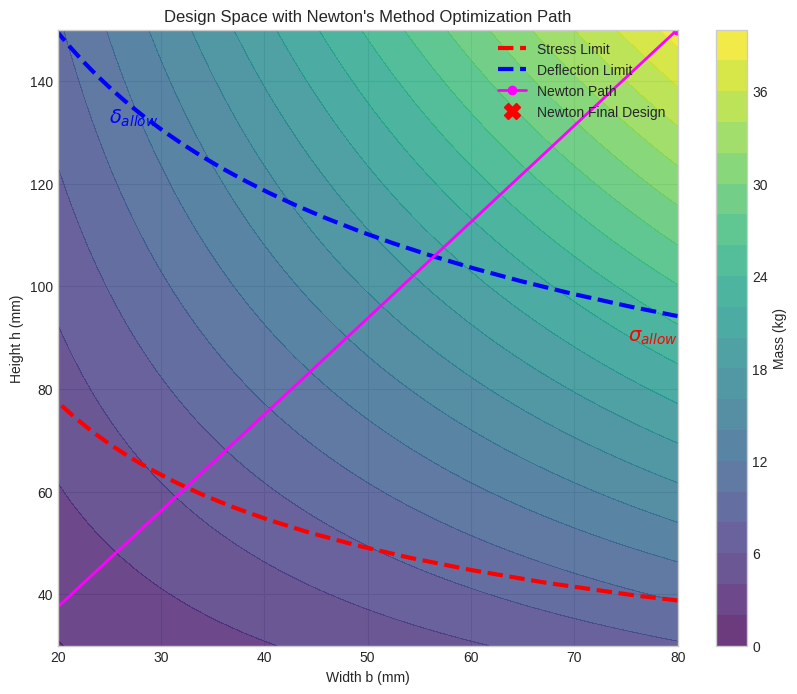

In [ ]:
# Plotting the optimization path for Newton's Method

fig, ax = plt.subplots(figsize=(10, 8))

# Contour plot of mass (from previous grid search)
contour_mass = ax.contourf(B * 1000, H * 1000, m_grid, levels=20, cmap='viridis', alpha=0.8)
fig.colorbar(contour_mass, ax=ax, label='Mass (kg)')

# Plot stress constraint boundary
stress_line = ax.contour(B * 1000, H * 1000, s_grid, levels=[sigma_allow], colors='red', linestyles='dashed', linewidths=3)
ax.text(b_max_mm, 0.5 * (h_min_mm + h_max_mm), r'$\sigma_{allow}$', color='red', fontsize=14, ha='right', va='center')

# Plot deflection constraint boundary
deflection_line = ax.contour(B * 1000, H * 1000, d_grid, levels=[delta_allow], colors='blue', linestyles='dashed', linewidths=3)
ax.text(b_min_mm + 5, 0.9 * h_max_mm, r'$\delta_{allow}$', color='blue', fontsize=14, ha='left', va='top')

# Plot Newton's method path
path_newton = np.array(iterations_newton)
ax.plot(path_newton[:, 0] * 1000, path_newton[:, 1] * 1000, 'o-', color='magenta', markersize=6, linewidth=2, label='Newton Path')
ax.plot(path_newton[-1, 0] * 1000, path_newton[-1, 1] * 1000, 'X', color='red', markersize=12, label='Newton Final Design')

ax.set_title('Design Space with Newton\'s Method Optimization Path')
ax.set_xlabel('Width b (mm)')
ax.set_ylabel('Height h (mm)')
ax.set_xlim(b_min_mm, b_max_mm)
ax.set_ylim(h_min_mm, h_max_mm)

# Custom legend handles
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='red', lw=3, ls='dashed', label='Stress Limit'),
    Line2D([0], [0], color='blue', lw=3, ls='dashed', label='Deflection Limit'),
    Line2D([0], [0], marker='o', color='magenta', label='Newton Path',
           markerfacecolor='magenta', markersize=6, linestyle='-', linewidth=2),
    Line2D([0], [0], marker='X', color='red', label='Newton Final Design',
           markerfacecolor='red', markersize=12, linestyle='None')
]
ax.legend(handles=legend_elements, loc='upper right')
ax.grid(True)
plt.show()


### Steepest Descent Method

The Steepest Descent method is another iterative optimization algorithm that moves in the direction opposite to the gradient of the objective function. It's simpler than Newton's method as it only uses the first derivative (gradient). The update rule is:

$$ \mathbf{x}_{k+1} = \mathbf{x}_k - \alpha_k \nabla f(\mathbf{x}_k) $$

Where $\alpha_k$ is the step size, often determined by a line search.

In [ ]:
# Implementation of Steepest Descent Method

iterations_steepest_descent = []

def steepest_descent(x_start, max_iter=100, tol=1e-6, alpha_initial=0.001):
    x = np.array(x_start, dtype=float)
    iterations_steepest_descent.append(x.copy())

    for i in range(max_iter):
        grad = gradient_penalized_objective(x)

        # Check for convergence
        if np.linalg.norm(grad) < tol:
            print(f"Steepest Descent converged in {i} iterations.")
            break

        # Determine step size (alpha) using a simple line search
        # A more robust line search (e.g., Armijo rule) would be used in practice.
        alpha = alpha_initial
        x_new = x - alpha * grad
        while penalized_objective(x_new) > penalized_objective(x) and alpha > 1e-6:
            alpha *= 0.5
            x_new = x - alpha * grad

        # If line search fails to find a better point, stop
        if penalized_objective(x_new) >= penalized_objective(x):
            print(f"Steepest Descent stalled at iteration {i}.")
            break

        # Update design variables
        x = x_new
        iterations_steepest_descent.append(x.copy())

        if i == max_iter - 1:
            print("Steepest Descent did not converge.")
    return x

# Initial guess for Steepest Descent method
x_initial_sd = np.array([0.05, 0.10])
optimal_x_sd = steepest_descent(x_initial_sd)

optimal_b_sd, optimal_h_sd = optimal_x_sd
m_opt_sd, s_opt_sd, d_opt_sd = beam_responses(optimal_b_sd, optimal_h_sd)

print(f"\nOptimal design (Steepest Descent Method):")
print(f"  b = {optimal_b_sd*1000:.2f} mm")
print(f"  h = {optimal_h_sd*1000:.2f} mm")
print(f"  Mass = {m_opt_sd:.2f} kg")
print(f"  Stress = {s_opt_sd/1e6:.1f} MPa (allowable: {sigma_allow/1e6:.1f} MPa)")
print(f"  Deflection = {d_opt_sd*1000:.2f} mm (allowable: {delta_allow*1000:.1f} mm)")
print(f"  Feasible: {s_opt_sd <= sigma_allow and d_opt_sd <= delta_allow}")


Steepest Descent stalled at iteration 7.

Optimal design (Steepest Descent Method):
  b = 23.18 mm
  h = 141.29 mm
  Mass = 10.61 kg
  Stress = 31.1 MPa (allowable: 120.0 MPa)
  Deflection = 3.06 mm (allowable: 3.0 mm)
  Feasible: False


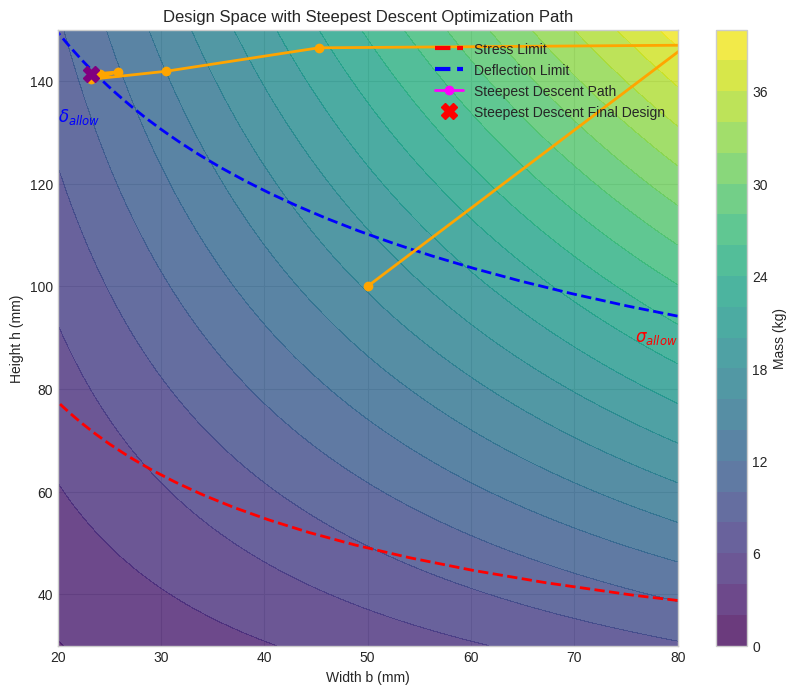

In [ ]:
# Plotting the optimization path for Steepest Descent Method

fig, ax = plt.subplots(figsize=(10, 8))

# Contour plot of mass (from previous grid search)
contour_mass = ax.contourf(B * 1000, H * 1000, m_grid, levels=20, cmap='viridis', alpha=0.8)
fig.colorbar(contour_mass, ax=ax, label='Mass (kg)')

# Plot stress constraint boundary
ax.contour(B * 1000, H * 1000, s_grid, levels=[sigma_allow], colors='red', linestyles='dashed', linewidths=2)
ax.text(b_max_mm, 0.5 * (h_min_mm + h_max_mm), r'$\sigma_{allow}$', color='red', fontsize=12, ha='right', va='center')

# Plot deflection constraint boundary
ax.contour(B * 1000, H * 1000, d_grid, levels=[delta_allow], colors='blue', linestyles='dashed', linewidths=2)
ax.text(b_min_mm, 0.9 * h_max_mm, r'$\delta_{allow}$', color='blue', fontsize=12, ha='left', va='top')

# Plot Steepest Descent path
path_sd = np.array(iterations_steepest_descent)
ax.plot(path_sd[:, 0] * 1000, path_sd[:, 1] * 1000, 'o-', color='orange', markersize=6, linewidth=2, label='Steepest Descent Path')
ax.plot(path_sd[-1, 0] * 1000, path_sd[-1, 1] * 1000, 'X', color='purple', markersize=12, label='Steepest Descent Final Design')

ax.set_title('Design Space with Steepest Descent Optimization Path')
ax.set_xlabel('Width b (mm)')
ax.set_ylabel('Height h (mm)')
ax.set_xlim(b_min_mm, b_max_mm)
ax.set_ylim(h_min_mm, h_max_mm)

# Custom legend handles
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='red', lw=3, ls='dashed', label='Stress Limit'),
    Line2D([0], [0], color='blue', lw=3, ls='dashed', label='Deflection Limit'),
    Line2D([0], [0], marker='o', color='magenta', label='Steepest Descent Path',
           markerfacecolor='magenta', markersize=6, linestyle='-', linewidth=2),
    Line2D([0], [0], marker='X', color='red', label='Steepest Descent Final Design',
           markerfacecolor='red', markersize=12, linestyle='None')
]
ax.legend(handles=legend_elements, loc='upper right')

ax.grid(True)
plt.show()
